## Load Stuff

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# If your file has multiple sheets:
df = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Reviews')
df_res = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Restaurants')

# 1. Text feature
df['Review Text'] = df['Review Text'].fillna('')

# 2. Categorical features → “Unknown” bucket
for col in ['Vegetarian?',
            'Marital Status',
            'Has Children?',
            'Preferred Mode of Transport']:
    df[col] = df[col].fillna('Unknown')

# 3. Numeric features → median imputation + missing‐flag
for col in ['Birth Year',
            'Weight (lb)',
            'Height (cm)']:
    df[f'{col}_missing'] = df[col].isna().astype(int)
    df[col] = df[col].fillna(df[col].median())

# Mode imputation for 'Average Amount Spent'
mode_value = df['Average Amount Spent'].mode()[0]
df['Average Amount Spent'] = df['Average Amount Spent'].fillna(mode_value)

## Question 1:

In [2]:
# Step 1: Drop duplicates to ensure one row per reviewer
df_unique = df.drop_duplicates(subset='Reviewer Name', keep='first').copy()

# Step 2: Define feature columns
numeric_cols = ['Birth Year', 'Weight (lb)', 'Height (cm)']
missing_flags = [f'{col}_missing' for col in numeric_cols]
categorical_cols = [
    'Vegetarian?',
    'Marital Status',
    'Has Children?',
    'Preferred Mode of Transport',
    'Average Amount Spent',
    'Northwestern Student?'
]

# Step 3: One-hot encode categorical features
df_encoded = pd.get_dummies(df_unique[categorical_cols], prefix=categorical_cols)

# Step 4: Concatenate numeric, missing flags, and one-hot features
df_user_vectors = pd.concat([
    df_unique[['Reviewer Name'] + numeric_cols + missing_flags],
    df_encoded
], axis=1)

# Step 5: Report total users and vector dimensionality
num_users = df_user_vectors.shape[0]
vector_dim = df_user_vectors.shape[1] - 1  # exclude 'Reviewer Name'

print(f"Total unique user vectors: {num_users}")
print(f"Dimensionality of each vector: {vector_dim}")

Total unique user vectors: 1089
Dimensionality of each vector: 28


## Question 2:

In [3]:
import numpy as np
from sklearn.metrics.pairwise import euclidean_distances

# Assume df_user_vectors and df (original review data) are already defined
df_user_vectors.reset_index(drop=True, inplace=True)
user_features = df_user_vectors.drop(columns=['Reviewer Name'])
user_names = df_user_vectors['Reviewer Name'].values

def recommend_from_most_similar_user(target_user_name: str, rating_threshold: int = 4):
    if target_user_name not in df_user_vectors['Reviewer Name'].values:
        raise ValueError(f"User '{target_user_name}' not found.")

    # Step 1: Get the target user's vector
    target_idx = df_user_vectors[df_user_vectors['Reviewer Name'] == target_user_name].index[0]
    target_vec = user_features.iloc[target_idx].values.reshape(1, -1)

    # Step 2: Compute pairwise distances to all others
    distances = euclidean_distances(target_vec, user_features.values).flatten()
    distance_df = pd.DataFrame({
        'Reviewer Name': user_names,
        'Distance': distances
    }).query("`Reviewer Name` != @target_user_name").sort_values(by='Distance')

    # Step 3: Most similar user
    most_similar_user = distance_df.iloc[0]['Reviewer Name']

    # Step 4: Get that user's reviews rated >= threshold
    similar_user_reviews = df[df['Reviewer Name'] == most_similar_user]
    top_reviews = similar_user_reviews[similar_user_reviews['Rating'] >= rating_threshold]

    # Step 5: Create list of (restaurant, rating) tuples
    recommended_restaurants_with_ratings = top_reviews[['Restaurant Name', 'Rating']].dropna().drop_duplicates()
    recommendations = recommended_restaurants_with_ratings.to_dict(orient='records')

    return {
        'target_user': target_user_name,
        'most_similar_user': most_similar_user,
        'recommended_restaurants': recommendations if recommendations else None
    }

# === Example Usage ===
result = recommend_from_most_similar_user('Timothy Mace', rating_threshold=4)
print("Recommendation Result:")
print(result)


Recommendation Result:
{'target_user': 'Timothy Mace', 'most_similar_user': 'Enid Egan', 'recommended_restaurants': [{'Restaurant Name': 'Burger King', 'Rating': 5}]}


## Question 3:

In [4]:
# Load the cleaned review data
# Assumes `df` is your cleaned DataFrame with columns: 'Reviewer Name', 'Restaurant Name', 'Rating'

# Step 1: Pivot table to create user × restaurant matrix
rating_matrix = df.pivot_table(
    index='Reviewer Name',
    columns='Restaurant Name',
    values='Rating'
)

# Step 2: Compute the mean rating for each restaurant (i.e., each column)
restaurant_means = rating_matrix.mean()

# Step 3: Fill missing ratings with the corresponding restaurant's mean
rating_matrix_filled = rating_matrix.fillna(restaurant_means)

# Optional: View a sample
print("Filled user–restaurant matrix (with restaurant averages for missing entries):")
print(rating_matrix_filled.head())

# Confirm shape: (num_users, num_restaurants)
print(f"Matrix shape: {rating_matrix_filled.shape}")


Filled user–restaurant matrix (with restaurant averages for missing entries):
Restaurant Name  5411 Empanadas    Alcove  Barn Steakhouse  \
Reviewer Name                                                
A B                    3.703704  3.631579              5.0   
Abigail                3.703704  3.631579              4.0   
Actual P.              3.703704  3.631579              4.0   
Adam Gibbons           3.703704  3.631579              4.0   
Agnes Zuber            3.703704  3.631579              4.0   

Restaurant Name  Brothers K Coffeehouse  Burger King  Campagnola  \
Reviewer Name                                                      
A B                            4.000000          1.8         4.0   
Abigail                        5.000000          1.8         4.0   
Actual P.                      4.533333          1.8         4.0   
Adam Gibbons                   4.533333          1.8         4.0   
Agnes Zuber                    4.533333          1.8         4.0   

Restaurant

In [5]:
def print_unrated_restaurants(rating_matrix):
    """
    Prints the names of restaurants (columns) that have never been rated by any user,
    and displays the total count.
    """
    # Identify columns where all values are NaN
    unrated_columns = rating_matrix.columns[rating_matrix.isna().all()].tolist()
    
    print("Restaurants with no ratings:")
    for name in unrated_columns:
        print("-", name)
    
    print(f"\nTotal number of unrated restaurants: {len(unrated_columns)}")

print_unrated_restaurants(rating_matrix)

Restaurants with no ratings:

Total number of unrated restaurants: 0


## Question 4:

In [6]:
from sklearn.metrics.pairwise import euclidean_distances
import pandas as pd

def compute_review_distances(user_name, rating_matrix):
    """
    Compute Euclidean distances from the given user to all others
    based on the filled user–restaurant rating matrix.

    Parameters:
        user_name (str): Name of the user to compare.
        rating_matrix (pd.DataFrame): Filled matrix of shape (users × restaurants).

    Returns:
        pd.DataFrame: Distances to all other users sorted in ascending order.
    """
    if user_name not in rating_matrix.index:
        raise ValueError(f"User '{user_name}' not found in the rating matrix.")
    
    user_vector = rating_matrix.loc[user_name].values.reshape(1, -1)
    distances = euclidean_distances(user_vector, rating_matrix.values).flatten()

    distance_df = pd.DataFrame({
        'Reviewer Name': rating_matrix.index,
        'Distance': distances
    }).query("`Reviewer Name` != @user_name").sort_values(by='Distance')
    
    return distance_df

def recommend_from_most_similar_user(user_name, rating_matrix, reviews_df):
    """
    Recommends restaurants rated ≥ 4 by the most similar user.

    Parameters:
        user_name (str): The user for whom to make recommendations.
        rating_matrix (pd.DataFrame): Filled user–restaurant rating matrix.
        reviews_df (pd.DataFrame): Original review DataFrame.

    Returns:
        dict: Contains target user, most similar user, and recommended restaurants with ratings.
    """
    rating_threshold = 4  # ← fixed rating threshold

    distances_df = compute_review_distances(user_name, rating_matrix)
    most_similar_user = distances_df.iloc[0]['Reviewer Name']

    similar_user_reviews = reviews_df[reviews_df['Reviewer Name'] == most_similar_user]
    top_reviews = similar_user_reviews[similar_user_reviews['Rating'] >= rating_threshold]

    recommended = top_reviews[['Restaurant Name', 'Rating']].drop_duplicates().reset_index(drop=True)

    return {
        'target_user': user_name,
        'most_similar_user': most_similar_user,
        'recommended_restaurants': recommended
    }

# === Run for 'Sarah Belle' ===
result = recommend_from_most_similar_user('Sarah Belle', rating_matrix_filled, df)

# Print results
print("Target User:", result['target_user'])
print("Most Similar User:", result['most_similar_user'])
print("Recommended Restaurants:")
print(result['recommended_restaurants'])


Target User: Sarah Belle
Most Similar User: Steven Johnston
Recommended Restaurants:
       Restaurant Name  Rating
0  Mumbai Indian Grill       5


## QUESTION 5 (Linear Regression)

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Step 1: Merge review and restaurant data
df_merged = pd.merge(df, df_res, on='Restaurant Name', how='left')

# Step 2: Define features
demo_features = [
    'Birth Year', 'Weight (lb)', 'Height (cm)',
    'Vegetarian?', 'Marital Status', 'Has Children?',
    'Preferred Mode of Transport', 'Average Amount Spent', 'Northwestern Student?'
]
cuisine_feature = ['Cuisine']

# Define categorical features to encode
categorical_features = [
    'Vegetarian?', 'Marital Status', 'Has Children?',
    'Preferred Mode of Transport', 'Average Amount Spent', 'Northwestern Student?',
    'Cuisine'
]

# Step 3: Prepare modeling DataFrame
df_model = df_merged[demo_features + cuisine_feature + ['Rating']].copy()

# Step 4: Handle missing values
# Numeric: median imputation
for col in ['Birth Year', 'Weight (lb)', 'Height (cm)']:
    df_model[col] = df_model[col].fillna(df_model[col].median())

# Categorical: fill with 'Unknown'
for col in categorical_features:
    df_model[col] = df_model[col].fillna('Unknown')

# Step 5: One-hot encode categorical features
df_encoded = pd.get_dummies(df_model, columns=categorical_features)

# Step 6: Split data into features (X) and target (y)
X_lin = df_encoded.drop(columns=['Rating'])
y_lin = df_encoded['Rating']

# Step 7: Train/test split
X_train_lin, X_test_lin, y_train_lin, y_test_lin = train_test_split(X_lin, y_lin, test_size=0.2, random_state=42)

# Step 8: Train Linear Regression model
model = LinearRegression()
model.fit(X_train_lin, y_train_lin)

# Step 9: Find y pred using model (will use later for finding MSE)
y_pred_lin = model.predict(X_test_lin)
mse = mean_squared_error(y_test_lin, y_pred_lin)
print(mse)

1.9538180334784716


In [8]:
# Step 8: Train Linear Regression model
model = LinearRegression()
model.fit(X_train_lin, y_train_lin)

# Step 9: Find y pred using model (will use later for finding MSE)
y_pred_lin = model.predict(X_test_lin)
mse = mean_squared_error(y_test_lin, y_pred_lin)
print(mse)

1.9538180334784716


## QUESTION 6 (Logistic Regression)

In [9]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Step 1: Merge review and restaurant data
df_merged = pd.merge(df, df_res, on='Restaurant Name', how='left')

# Step 2: Define demographic and restaurant features
demo_features = [
    'Birth Year', 'Weight (lb)', 'Height (cm)',
    'Vegetarian?', 'Marital Status', 'Has Children?',
    'Preferred Mode of Transport', 'Average Amount Spent', 'Northwestern Student?'
]
cuisine_feature = ['Cuisine']

categorical_features = [
    'Vegetarian?', 'Marital Status', 'Has Children?',
    'Preferred Mode of Transport', 'Average Amount Spent', 'Northwestern Student?',
    'Cuisine'
]

# ------------ Step 3: Prepare modeling DataFrame with the predicotrs and Rating as outcome variable ------------------------
df_model = df_merged[demo_features + cuisine_feature + ['Rating']].copy()


# ------------------------------------------------------------------------------------------------------
# ------------ Step 4: Binarize ratings → 1 (positive, ≥ 4), 0 (negative, ≤ 3) ------------------------
# ------------------------------------------------------------------------------------------------------
df_model = df_model[df_model['Rating'].notna()] # make sure no NaN in Rating col
df_model['Label'] = (df_model['Rating'] >= 4).astype(int) # create new binary column


# ------------------------------------------------------------------------------------------------------
# ------------------------ Step 5: Imputations ------------------------
# ------------------------------------------------------------------------------------------------------
# Impute missing values using median for the continuous variables
for col in ['Birth Year', 'Weight (lb)', 'Height (cm)']:
    df_model[col] = df_model[col].fillna(df_model[col].median())

# impute missing values with separate "unknown" category for categorical variables
for col in categorical_features:
    df_model[col] = df_model[col].fillna('Unknown')

# ------------------------------------------------------------------------------------------------------
# ------------------------ Step 6: One-hot encode categorical variables for each review ------------------------
# ------------------------------------------------------------------------------------------------------
# pd.get_dummies(df) creates a new df with one hot encodings for each row
df_encoded = pd.get_dummies(df_model.drop(columns=['Rating']), columns=categorical_features)


# ------------------------------------------------------------------------------------------------------
# ------------------------ Step 7: Extract X and y from df_encoded ------------------------
# ------------------------------------------------------------------------------------------------------
X_log = df_encoded.drop(columns=['Label'])
y_log = df_encoded['Label']


# ------------------------------------------------------------------------------------------------------
# ------------------------ Step 8: Split ur dataset into train + test split using train_test_split function
# ------------------------------------------------------------------------------------------------------
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(X_log, y_log, test_size=0.2, random_state=42)


# ------------------------------------------------------------------------------------------------------
# ------------------------ Step 9: Train logistic regression to get params using the training data
# ------------------------------------------------------------------------------------------------------
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_log, y_train_log) 


# ------------------------------------------------------------------------------------------------------
# ------------------------ Step 10: Find y pred for this model ------------------------
# ------------------------------------------------------------------------------------------------------
y_pred_log = log_model.predict(X_test_log)
accuracy = accuracy_score(y_test_log, y_pred_log)
report = classification_report(y_test_log, y_pred_log)

# Output
print(f"Accuracy: {accuracy:.4f}")
print("Classification Report:")
print(report)


Accuracy: 0.7067
Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.30      0.40        97
           1       0.73      0.90      0.81       203

    accuracy                           0.71       300
   macro avg       0.66      0.60      0.60       300
weighted avg       0.68      0.71      0.67       300



/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


## Question 7 (Compare lin and log models)
Compare the performance of linear and logistic regression by creating a train/test split on your model? What is the error of your models? 

How should you compare them?

Select a review from the test set and use your model to predict the restaurant score based on his user demographics and the restaurant's cuisine type. Compare the model's prediction with the actual score to assess its accuracy.

In [10]:
# === Step 11: Pick one review from test set ===
sample_idx = X_test_lin.index[0]
X_sample = X_test_lin.loc[[sample_idx]]  # keep as DataFrame with column names

# Predict using both models
predicted_rating = model.predict(X_sample)[0]
predicted_label = log_model.predict(X_sample)[0]

# True values
true_rating = y_test_lin.loc[sample_idx]  # for linear
true_label = y_test_log.loc[sample_idx]   # for logistic (same binary y if reused)

# === Step 12: Output Summary ===
print("🔍 Model Performance Comparison:")
print(f"- Linear Regression Mean Squared Error (MSE): {mse:.4f}")
print(f"- Logistic Regression Accuracy: {accuracy:.4f}")
print("\n📊 Logistic Regression Classification Report:")
print(report)

print("\n📌 Sample Review Comparison:")
print(f"- Actual Rating: {true_rating}")
print(f"- Linear Predicted Rating: {predicted_rating:.2f}")
print(f"- Actual Label (1=positive): {true_label}")
print(f"- Logistic Predicted Label: {predicted_label}")

🔍 Model Performance Comparison:
- Linear Regression Mean Squared Error (MSE): 1.9538
- Logistic Regression Accuracy: 0.7067

📊 Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.30      0.40        97
           1       0.73      0.90      0.81       203

    accuracy                           0.71       300
   macro avg       0.66      0.60      0.60       300
weighted avg       0.68      0.71      0.67       300


📌 Sample Review Comparison:
- Actual Rating: 5
- Linear Predicted Rating: 2.87
- Actual Label (1=positive): 1
- Logistic Predicted Label: 0


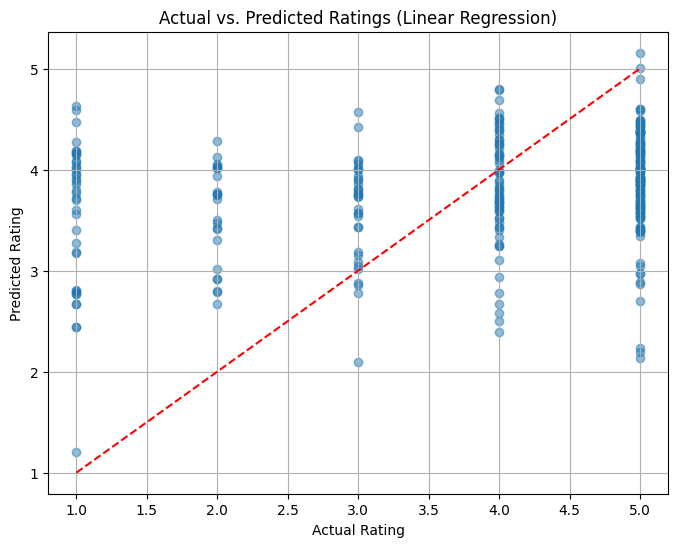

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test_lin, y_pred_lin, alpha=0.5)
plt.plot([y_test_lin.min(), y_test_lin.max()], [y_test_lin.min(), y_test_lin.max()], 'r--')  # ideal line
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs. Predicted Ratings (Linear Regression)")
plt.grid(True)
plt.show()


## QUESTION 8 (Lasso Regularization)

In [12]:
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler

# Step 1: Merge and prepare data
df_merged = pd.merge(df, df_res, on='Restaurant Name', how='left')

# Define features
demo_features = [
    'Birth Year', 'Weight (lb)', 'Height (cm)',
    'Vegetarian?', 'Marital Status', 'Has Children?',
    'Preferred Mode of Transport', 'Average Amount Spent', 'Northwestern Student?'
]
cuisine_feature = ['Cuisine']
categorical_features = demo_features[3:] + cuisine_feature

# Prepare DataFrame
df_model = df_merged[demo_features + cuisine_feature + ['Rating']].dropna(subset=['Rating']).copy()

# Impute missing values
for col in ['Birth Year', 'Weight (lb)', 'Height (cm)']:
    df_model[col] = df_model[col].fillna(df_model[col].median())
for col in categorical_features:
    df_model[col] = df_model[col].fillna('Unknown')

# One-hot encode categorical features
df_encoded = pd.get_dummies(df_model, columns=categorical_features)

# Separate target and features
X = df_encoded.drop(columns=['Rating'])
y = df_encoded['Rating']

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Scale continuous features
# Identify numeric columns (those that were not one-hot encoded)
numeric_cols = ['Birth Year', 'Weight (lb)', 'Height (cm)']
scaler = StandardScaler()
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

# Step 3: Train standard linear regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
linear_mse = mean_squared_error(y_test, linear_model.predict(X_test))

# Step 4: Train Lasso regression
lasso_model = Lasso(alpha=0.1)
lasso_model.fit(X_train, y_train)
lasso_preds = lasso_model.predict(X_test)
lasso_mse = mean_squared_error(y_test, lasso_preds)

# Step 5: Analyze Lasso coefficients
coefficients = lasso_model.coef_
feature_names = X_train.columns
selected_features = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

# Select only non-zero weights
selected_nonzero = selected_features[coefficients != 0].copy()
selected_nonzero_sorted = selected_nonzero.sort_values(by='Coefficient', ascending=False)

# Step 6: Output comparison
print("🔍 Model Performance Comparison")
print(f"- Linear Regression MSE: {linear_mse:.4f}")
print(f"- Lasso Regression MSE: {lasso_mse:.4f}")
print(f"- Features selected by Lasso (non-zero weights): {len(selected_nonzero)}")

print("\n📈 Top Positive Predictive Features (Lasso):")
print(selected_nonzero_sorted.head(10))

print("\n📉 Top Negative Predictive Features (Lasso):")
print(selected_nonzero_sorted.tail(10))


🔍 Model Performance Comparison
- Linear Regression MSE: 1.9538
- Lasso Regression MSE: 2.0256
- Features selected by Lasso (non-zero weights): 1

📈 Top Positive Predictive Features (Lasso):
      Feature  Coefficient
0  Birth Year     0.010822

📉 Top Negative Predictive Features (Lasso):
      Feature  Coefficient
0  Birth Year     0.010822


## Question 9 (Demographic features predicting coffee scores)

In [13]:
# Filter to coffee shops, and obtain subdataset df_coffee
coffee_shops = ["Peet's Coffee", "Pâtisserie Coralie", "Philz Coffee", "Brothers K Coffee"]  # update names if needed
df_coffee = df[df['Restaurant Name'].isin(coffee_shops)].copy()
rare_modes = ['Public Transit', 'Unknown']
df_coffee['Preferred Mode of Transport'] = df_coffee['Preferred Mode of Transport'].replace(rare_modes, 'Other')


# # Merge with restaurant data (optional)
# df_coffee = pd.merge(df_coffee, df_res, on='Restaurant Name', how='left')

# Define demographic features
demo_features = [
    'Birth Year', 'Weight (lb)', 'Height (cm)',
    'Vegetarian?', 'Marital Status', 'Has Children?',
    'Preferred Mode of Transport', 'Average Amount Spent', 'Northwestern Student?'
]
categorical_features = demo_features[3:]

# Filter and encode data
df_model = df_coffee[demo_features + ['Rating']].dropna(subset=['Rating']).copy()
for col in categorical_features:
    df_model[col] = df_model[col].fillna('Unknown')
df_encoded = pd.get_dummies(df_model, columns=categorical_features, drop_first=True)

# Train/test split
X = df_encoded.drop(columns=['Rating'])
y = df_encoded['Rating']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)

# Show results
print(f"Linear Regression MSE (Coffee Shops): {mse:.4f}")

# Show top coefficients
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
}).sort_values(by='Coefficient', ascending=False)

print("\nTop Positive Coefficients:")
print(coef_df.head(10))

print("\nTop Negative Coefficients:")
print(coef_df.tail(10))


Linear Regression MSE (Coffee Shops): 2.7752

Top Positive Coefficients:
                                Feature  Coefficient
4                       Vegetarian?_Yes     1.925023
10    Preferred Mode of Transport_Other     1.402221
13            Northwestern Student?_Yes     1.226526
3                   Vegetarian?_Unknown     0.831005
6                Marital Status_Unknown     0.110774
7                 Has Children?_Unknown     0.110774
2                           Height (cm)     0.016740
1                           Weight (lb)     0.007220
0                            Birth Year    -0.001452
9   Preferred Mode of Transport_On Foot    -0.256594

Top Negative Coefficients:
                                Feature  Coefficient
6                Marital Status_Unknown     0.110774
7                 Has Children?_Unknown     0.110774
2                           Height (cm)     0.016740
1                           Weight (lb)     0.007220
0                            Birth Year    -0.00145

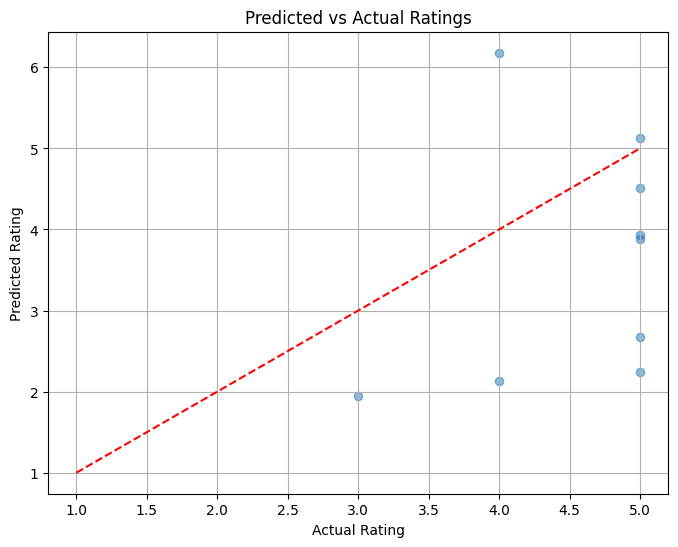

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([1, 5], [1, 5], color='red', linestyle='--')  # ideal line
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Predicted vs Actual Ratings")
plt.grid(True)
plt.show()


In [15]:
df_coffee['Preferred Mode of Transport'].value_counts()


Preferred Mode of Transport
Car Owner    29
On Foot      13
Other         3
Name: count, dtype: int64

## Question 11

In [16]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics import accuracy_score, classification_report, mean_squared_error

# Load your review data (already cleaned)
df = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Reviews')
df['Review Text'] = df['Review Text'].fillna('')

# 2. Label sentiment
df = df[df['Rating'].notna()].copy()
df['Label'] = (df['Rating'] >= 4).astype(int)

# 3. Generate review embeddings
model_name = 'all-MiniLM-L6-v2'
embedder = SentenceTransformer(model_name)
review_texts = df['Review Text'].tolist()
embeddings = embedder.encode(review_texts, show_progress_bar=True)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    embeddings, df['Label'], test_size=0.2, random_state=42
)

# 5. Train logistic regression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

# 6. Evaluate performance
y_pred = logreg.predict(X_test)
y_pred_proba = logreg.predict_proba(X_test)[:, 1]  # for MSE

accuracy = accuracy_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred_proba)

print(f"🔍 Logistic Regression with Review Embeddings")
print(f"- Accuracy: {accuracy:.4f}")
print(f"- MSE: {mse:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


/Users/chan/miniconda3/envs/stat415_hw3_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Batches: 100%|██████████| 47/47 [00:07<00:00,  6.24it/s]

🔍 Logistic Regression with Review Embeddings
- Accuracy: 0.7967
- MSE: 0.1409

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.45      0.59        97
           1       0.79      0.96      0.86       203

    accuracy                           0.80       300
   macro avg       0.82      0.71      0.73       300
weighted avg       0.81      0.80      0.78       300



## Question 12 (Final)

In [17]:
import pandas as pd

# Load data
df = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Reviews')
df_res = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Restaurants')

# Merge review + restaurant info
df_merged = pd.merge(df, df_res, on='Restaurant Name', how='left')

# Filter out missing ratings and student info
df_merged = df_merged[df_merged['Rating'].notna()]
df_merged['Northwestern Student?'] = df_merged['Northwestern Student?'].fillna('Unknown')

# Average rating by NW student status
student_avg = df_merged.groupby('Northwestern Student?')['Rating'].mean()
print("📊 Average Rating by Northwestern Student Status:")
print(student_avg)

# Average rating by student + cuisine
student_cuisine = df_merged.groupby(['Northwestern Student?', 'Cuisine'])['Rating'].mean().unstack()
print("\n📊 Average Rating by Student Status and Cuisine:")
print(student_cuisine)

# Average rating by student + restaurant
student_rest = df_merged.groupby(['Northwestern Student?', 'Restaurant Name'])['Rating'].mean().unstack()
print("\n📊 Average Rating by Student Status and Restaurant:")
print(student_rest)

# Optional: how many reviews per group
counts = df_merged.groupby(['Northwestern Student?'])['Rating'].count()
print("\n🧮 Number of Reviews by Group:")
print(counts)


📊 Average Rating by Northwestern Student Status:
Northwestern Student?
No     3.728550
Yes    3.898649
Name: Rating, dtype: float64

📊 Average Rating by Student Status and Cuisine:
Cuisine                American       BBQ  Breakfast   Brewery  Bubble Tea  \
Northwestern Student?                                                        
No                     3.374150  3.555556   4.130435  4.296296     4.16129   
Yes                    3.714286       NaN        NaN  5.000000         NaN   

Cuisine                 Burgers   Chinese  Chocolate    Coffee  Deli  ...  \
Northwestern Student?                                                 ...   
No                     2.741573  3.736842   3.789474  4.127660   4.5  ...   
Yes                    2.800000  3.750000   5.000000  4.928571   3.0  ...   

Cuisine                  Korean  Mediterranean  Mexican     Pizza     Salad  \
Northwestern Student?                                                         
No                     4.054054       3

/var/folders/nz/dzmdyljd0f7cgh05j0bjzv7h0000gn/T/ipykernel_21496/4012179874.py:21: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(ax=axes[0], data=df_merged, x='Northwestern Student?', y='Rating', ci=None)


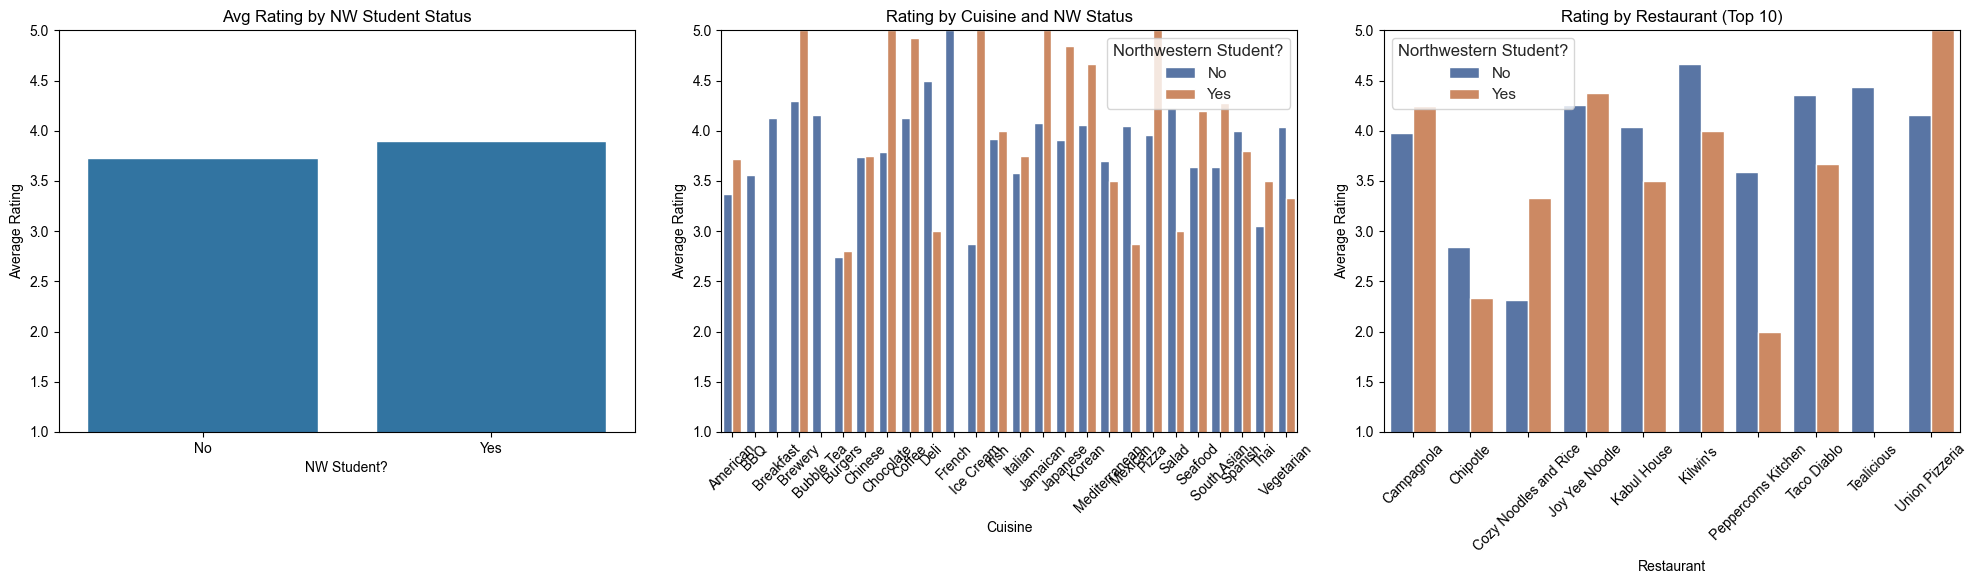

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Reviews')
df_res = pd.read_excel('evanston_restaurant_data.xlsx', sheet_name='Restaurants')

# Merge datasets
df_merged = pd.merge(df, df_res, on='Restaurant Name', how='left')

# Clean data
df_merged = df_merged[df_merged['Rating'].notna()]
df_merged['Northwestern Student?'] = df_merged['Northwestern Student?'].fillna('Unknown')

# Setup subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.set(style="whitegrid")

# === 1. Avg Rating by Student Status ===
sns.barplot(ax=axes[0], data=df_merged, x='Northwestern Student?', y='Rating', ci=None)
axes[0].set_title('Avg Rating by NW Student Status')
axes[0].set_ylim(1, 5)
axes[0].set_xlabel('NW Student?')
axes[0].set_ylabel('Average Rating')

# === 2. Avg Rating by Cuisine and Student Status ===
cuisine_group = df_merged.groupby(['Northwestern Student?', 'Cuisine'])['Rating'].mean().reset_index()
sns.barplot(ax=axes[1], data=cuisine_group, x='Cuisine', y='Rating', hue='Northwestern Student?')
axes[1].set_title('Rating by Cuisine and NW Status')
axes[1].set_ylim(1, 5)
axes[1].set_xlabel('Cuisine')
axes[1].set_ylabel('Average Rating')
axes[1].tick_params(axis='x', rotation=45)

# === 3. Avg Rating for Top 10 Reviewed Restaurants ===
top_restaurants = df_merged['Restaurant Name'].value_counts().head(10).index
subset_df = df_merged[df_merged['Restaurant Name'].isin(top_restaurants)]
rest_group = subset_df.groupby(['Northwestern Student?', 'Restaurant Name'])['Rating'].mean().reset_index()
sns.barplot(ax=axes[2], data=rest_group, x='Restaurant Name', y='Rating', hue='Northwestern Student?')
axes[2].set_title('Rating by Restaurant (Top 10)')
axes[2].set_ylim(1, 5)
axes[2].set_xlabel('Restaurant')
axes[2].set_ylabel('Average Rating')
axes[2].tick_params(axis='x', rotation=45)

# Final layout
plt.tight_layout()
plt.show()
